In [1]:
%pip install prophet tensorflow mlflow

import os, warnings, json, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("D:\ProjectMaterail\RetailPulse\RetailPulse\online_retail_II.xlsx|")
                                                                             
if not DATA_PATH.exists():
    DATA_PATH = Path("D:\ProjectMaterail\RetailPulse\RetailPulse\online_retail_II.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/online_retail_II.xlsx")

OUTPUT_DIR = Path("../data/processed")
REPORT_DIR = Path("../reports")
MODEL_DIR = Path("../models")
for folder in [OUTPUT_DIR, REPORT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATA_PATH.resolve())
print("Dataset found:", DATA_PATH.exists())

<>:14: SyntaxWarning: invalid escape sequence '\P'
<>:17: SyntaxWarning: invalid escape sequence '\P'
<>:14: SyntaxWarning: invalid escape sequence '\P'
<>:17: SyntaxWarning: invalid escape sequence '\P'
C:\Users\govin\AppData\Local\Temp\ipykernel_21272\3646885516.py:14: SyntaxWarning: invalid escape sequence '\P'
  DATA_PATH = Path("D:\ProjectMaterail\RetailPulse\RetailPulse\online_retail_II.xlsx|")
C:\Users\govin\AppData\Local\Temp\ipykernel_21272\3646885516.py:17: SyntaxWarning: invalid escape sequence '\P'
  DATA_PATH = Path("D:\ProjectMaterail\RetailPulse\RetailPulse\online_retail_II.xlsx")


  Using cached prophet-1.5.0-py3-none-win_amd64.whl.metadata (3.7 kB)
  Using cached mlflow-3.17.2-py3-none-any.whl.metadata (50 kB)
  Using cached cmdstanpy-1.3.0-py3-none-any.whl.metadata (4.2 kB)
  Using cached holidays-0.108-py3-none-any.whl.metadata (57 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached mlflow_skinny-3.17.2-py3-none-any.whl.metadata (51 kB)
  Using cached mlflow_tracing-3.17.2-py3-none-any.whl.metadata (19 kB)
  Using cached flask_cors-6.0.5-py3-none-any.whl.metadata (5.4 kB)
  Using cached alembic-1.20.1-py3-none-any.whl.metadata (7.3 kB)
  Using cached cryptography-50.0.2-cp311-abi3-win_amd64.whl.metadata (4.4 kB)
  Using cached docker-7.2.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached graphene-3.4.3-py2.py3-none-any.whl.metadata (6.9 kB)
  Using cached huey-3.5.4-py3-none-any.whl.metadata (5.7 kB)
  Using cached skops-0.16.0-py3-none-any.whl.metadata (4.3 kB)
  Using cached waitress-3.0.2-py3-none-any.whl.metadata (5.8 kB)
  Us

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

Dataset path: D:\ProjectMaterail\RetailPulse\RetailPulse\online_retail_II.xlsx
Dataset found: True


In [2]:
assert DATA_PATH.exists(), (
    "Workbook not found. Place online_retail_II.xlsx in data/raw/ "
    "or update DATA_PATH in this notebook."
)

try:
    import openpyxl              
except ImportError:
    %pip install openpyxl
    import openpyxl              

sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine="openpyxl")
raw_df = pd.concat(sheets.values(), ignore_index=True)
print("Sheets loaded:", list(sheets.keys()))
print("Combined shape:", raw_df.shape)
display(raw_df.head())

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
EXPECTED_COLUMNS = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Expected columns missing from workbook: {missing_columns}")

raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [4]:
quality_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
    "dtype": raw_df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)
display(quality_summary)

,missing_count,missing_pct,dtype
Customer ID,243007,22.77,float64
Description,4382,0.41,object
StockCode,0,0.00,object
Invoice,0,0.00,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[us]
Price,0,0.00,float64
Country,0,0.00,str


In [5]:
print("Exact duplicate rows:", raw_df.duplicated().sum())
print("Date range:", raw_df["InvoiceDate"].min(), "to", raw_df["InvoiceDate"].max())
print("Unique countries:", raw_df["Country"].nunique())
print("Unique invoice values:", raw_df["Invoice"].nunique())
print("Unique stock codes:", raw_df["StockCode"].nunique())

Exact duplicate rows: 34335
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique countries: 43
Unique invoice values: 53628
Unique stock codes: 5305


In [6]:
df = raw_df.copy()
df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Customer ID"] = pd.to_numeric(df["Customer ID"], errors="coerce")

df = df.dropna(subset=["InvoiceDate", "StockCode", "Quantity", "Price"])
returns_summary = df.loc[(df["Quantity"] <= 0) | (df["Price"] <= 0)].copy()
sales_df = df.loc[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
sales_df["Customer ID"] = sales_df["Customer ID"].astype("Int64")
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]
sales_df["InvoiceMonth"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)
sales_df["InvoiceDay"] = sales_df["InvoiceDate"].dt.date

print("Cleaned sales shape:", sales_df.shape)
print("Returns/cancellations/non-positive records set aside:", returns_summary.shape[0])
display(sales_df.head())

Cleaned sales shape: (1007914, 11)
Returns/cancellations/non-positive records set aside: 25122


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,InvoiceMonth,InvoiceDay
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12,2009-12-01


In [7]:
cleaning_summary = pd.DataFrame({
    "stage": ["Raw combined", "After duplicate removal", "Valid core fields", "Positive quantity & price"],
    "rows": [len(raw_df), len(raw_df.drop_duplicates()),
             len(df), len(sales_df)]
})
display(cleaning_summary)

,stage,rows
0,Raw combined,1067371
1,After duplicate removal,1033036
2,Valid core fields,1033036
3,Positive quantity & price,1007914


In [8]:
eda_kpis = {
    "Rows in cleaned sales": len(sales_df),
    "Gross revenue": sales_df["Revenue"].sum(),
    "Units sold": sales_df["Quantity"].sum(),
    "Unique customers (identified)": sales_df["Customer ID"].nunique(),
    "Unique products": sales_df["StockCode"].nunique(),
    "Invoices": sales_df["Invoice"].nunique(),
}
display(pd.Series(eda_kpis, name="value"))

Rows in cleaned sales            1.007914e+06
Gross revenue                    2.047663e+07
Units sold                       1.120515e+07
Unique customers (identified)    5.878000e+03
Unique products                  4.917000e+03
Invoices                         4.007800e+04
Name: value, dtype: float64

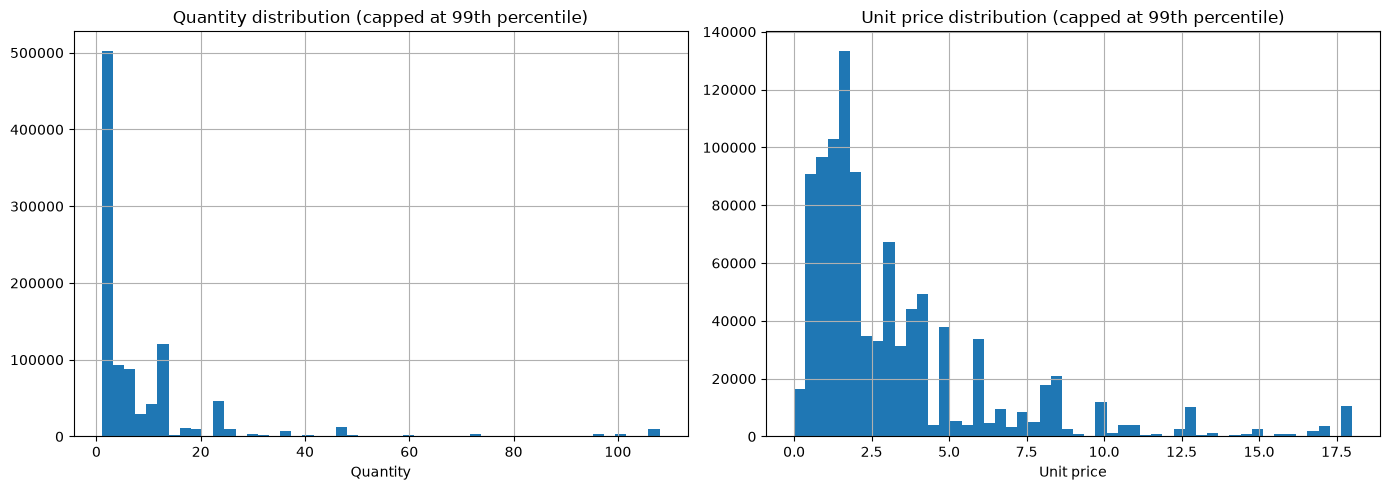

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sales_df["Quantity"].clip(upper=sales_df["Quantity"].quantile(.99)).hist(bins=50, ax=axes[0])
axes[0].set_title("Quantity distribution (capped at 99th percentile)")
axes[0].set_xlabel("Quantity")
sales_df["Price"].clip(upper=sales_df["Price"].quantile(.99)).hist(bins=50, ax=axes[1])
axes[1].set_title("Unit price distribution (capped at 99th percentile)")
axes[1].set_xlabel("Unit price")
plt.tight_layout()
plt.show()

In [10]:
monthly_sales = sales_df.groupby("InvoiceMonth", as_index=False).agg(
    revenue=("Revenue", "sum"),
    units=("Quantity", "sum"),
    invoices=("Invoice", "nunique"),
    customers=("Customer ID", "nunique")
)
monthly_sales["month"] = pd.to_datetime(monthly_sales["InvoiceMonth"])
monthly_sales = monthly_sales.sort_values("month")
display(monthly_sales.head())

,InvoiceMonth,revenue,units,invoices,customers,month
0,2009-12,822483.950,425461,1682,955,2009-12-01
1,2010-01,651155.112,390672,1105,720,2010-01-01
2,2010-02,551878.296,381880,1202,772,2010-02-01
3,2010-03,830915.261,526026,1681,1057,2010-03-01
4,2010-04,678875.252,366705,1462,942,2010-04-01


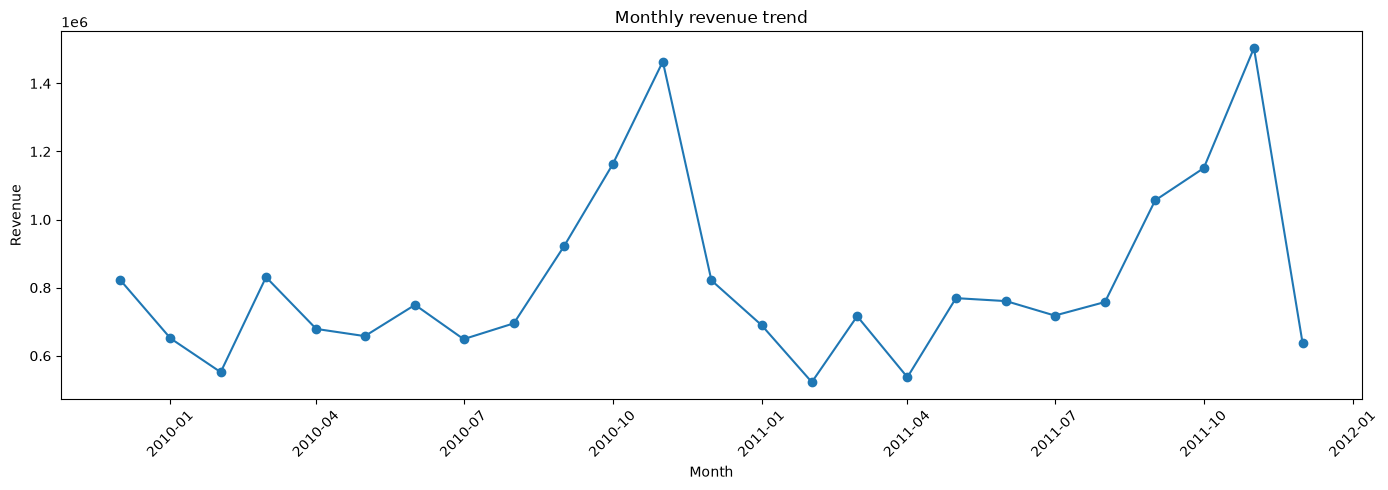

In [11]:
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales["month"], monthly_sales["revenue"], marker="o")
plt.title("Monthly revenue trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

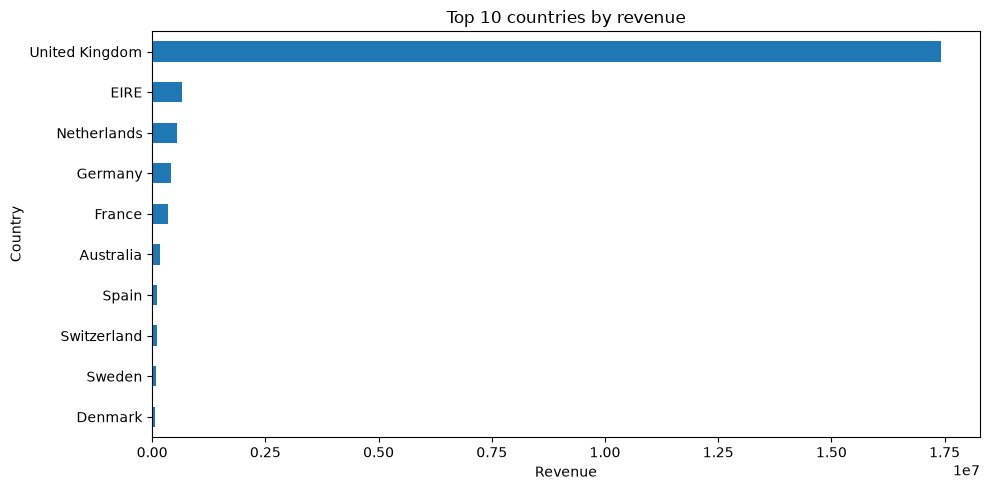

,revenue
Country,
United Kingdom,1.741057e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


In [12]:
top_countries = sales_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind="barh")
plt.title("Top 10 countries by revenue")
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()
display(top_countries.to_frame("revenue"))

In [13]:
top_products = sales_df.groupby(["StockCode", "Description"], dropna=False).agg(
    revenue=("Revenue", "sum"), units=("Quantity", "sum")
).sort_values("revenue", ascending=False).head(15)
display(top_products)

,,revenue,units
StockCode,Description,,
M,Manual,339599.81,9630
22423,REGENCY CAKESTAND 3 TIER,330590.32,26478
DOT,DOTCOM POSTAGE,309854.11,1415
85123A,WHITE HANGING HEART T-LIGHT HOLDER,257546.20,94142
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
47566,PARTY BUNTING,148318.28,28200
85099B,JUMBO BAG RED RETROSPOT,145961.83,77280
84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,80082
POST,POSTAGE,125682.42,5363


In [14]:
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.dayofweek
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour
sales_df["IsWeekend"] = sales_df["DayOfWeek"].isin([5, 6]).astype(int)

                                                                                 
daily_product_demand = sales_df.groupby(
    [sales_df["InvoiceDate"].dt.floor("D"), "StockCode"], as_index=False
).agg(
    daily_units=("Quantity", "sum"),
    daily_revenue=("Revenue", "sum")
).rename(columns={"InvoiceDate": "Date"})
daily_product_demand["Date"] = pd.to_datetime(daily_product_demand["Date"])
display(daily_product_demand.head())

,Date,StockCode,daily_units,daily_revenue
0,2009-12-01,10002,12,10.20
1,2009-12-01,10120,60,12.60
2,2009-12-01,10125,5,5.10
3,2009-12-01,10133,6,5.10
4,2009-12-01,10135,17,21.25


In [15]:
customer_df = sales_df.dropna(subset=["Customer ID"]).copy()
snapshot_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    LastPurchase=("InvoiceDate", "max"),
    FirstPurchase=("InvoiceDate", "min")
).reset_index()
rfm["AverageOrderValue"] = rfm["Monetary"] / rfm["Frequency"].replace(0, np.nan)
display(rfm.describe(include="all").T)
display(rfm.head())

,count,mean,min,25%,50%,75%,max,std
Customer ID,5878.0,15315.313542,12346.0,13833.25,15314.5,16797.75,18287.0,1715.572666
Recency,5878.0,201.331916,1.0,26.0,96.0,380.0,739.0,209.338707
Frequency,5878.0,6.289384,1.0,1.0,3.0,7.0,398.0,13.009406
Monetary,5878.0,2955.904095,2.95,342.28,867.74,2248.305,580987.04,14440.852688
LastPurchase,5878,2011-05-22 16:19:59.469207,2009-12-01 09:55:00,2010-11-25 10:24:45,2011-09-05 11:59:00,2011-11-14 11:31:15,2011-12-09 12:50:00,NaN
FirstPurchase,5878,2010-08-22 06:57:33.297039,2009-12-01 07:45:00,2010-02-09 14:01:15,2010-06-27 13:31:30,2011-01-30 14:30:15,2011-12-09 12:16:00,NaN
AverageOrderValue,5878.0,385.180841,2.95,176.6825,279.242679,414.902458,84236.25,1214.286459


,Customer ID,Recency,Frequency,Monetary,LastPurchase,FirstPurchase,AverageOrderValue
0,12346,326,12,77556.46,2011-01-18 10:01:00,2009-12-14 08:34:00,6463.038333
1,12347,2,8,4921.53,2011-12-07 15:52:00,2010-10-31 14:20:00,615.191250
2,12348,75,5,2019.40,2011-09-25 13:13:00,2010-09-27 14:59:00,403.880000
3,12349,19,4,4428.69,2011-11-21 09:51:00,2010-04-29 13:20:00,1107.172500
4,12350,310,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000


In [16]:
                                                                                       
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)

def rfm_segment(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "Champions"
    if row["R_Score"] >= 3 and row["F_Score"] >= 2:
        return "Loyal / Active"
    if row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    if row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost / Hibernating"
    return "Potential / Other"

rfm["Segment"] = rfm.apply(rfm_segment, axis=1)
display(rfm.groupby("Segment").agg(
    customers=("Customer ID", "nunique"),
    mean_recency=("Recency", "mean"),
    mean_frequency=("Frequency", "mean"),
    total_monetary=("Monetary", "sum")
).sort_values("customers", ascending=False))

,customers,mean_recency,mean_frequency,total_monetary
Segment,,,,
Lost / Hibernating,2051,410.635787,1.486104,1.120227e+06
Champions,1813,29.008825,14.099283,1.315866e+07
At Risk,888,275.493243,6.539414,2.192697e+06
Loyal / Active,792,35.998737,2.800505,7.733429e+05
Potential / Other,334,46.326347,1.000000,1.298758e+05


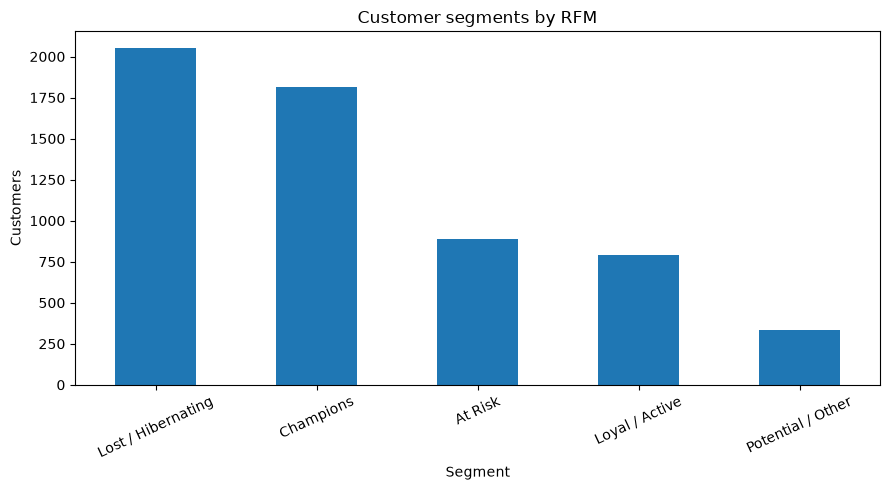

In [17]:
plt.figure(figsize=(9, 5))
rfm["Segment"].value_counts().plot(kind="bar")
plt.title("Customer segments by RFM")
plt.ylabel("Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [18]:
data_end = customer_df["InvoiceDate"].max().normalize()
snapshot = data_end - pd.Timedelta(days=90)
outcome_end = snapshot + pd.Timedelta(days=90)

historical = customer_df[customer_df["InvoiceDate"] <= snapshot].copy()
future = customer_df[(customer_df["InvoiceDate"] > snapshot) &
                     (customer_df["InvoiceDate"] <= outcome_end)].copy()

churn_features = historical.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    MeanBasketUnits=("Quantity", "mean"),
    UniqueProducts=("StockCode", "nunique"),
).reset_index()

future_active_ids = set(future["Customer ID"].dropna().astype(int).unique())
churn_features["ChurnProxy"] = (~churn_features["Customer ID"].astype(int).isin(future_active_ids)).astype(int)
print("Snapshot:", snapshot.date(), "| Outcome window end:", outcome_end.date())
print(churn_features["ChurnProxy"].value_counts())
display(churn_features.head())

Snapshot: 2011-09-10 | Outcome window end: 2011-12-09
ChurnProxy
1    2991
0    2290
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,MeanBasketUnits,UniqueProducts,ChurnProxy
0,12346,234,12,77556.46,2184.852941,27,1
1,12347,38,6,3402.39,12.798780,107,0
2,12348,157,4,1709.40,52.020833,25,0
3,12349,316,3,2671.14,9.735294,90,0
4,12350,219,1,334.40,11.588235,17,1


              precision    recall  f1-score   support

           0       0.66      0.67      0.67       573
           1       0.75      0.74      0.74       748

    accuracy                           0.71      1321
   macro avg       0.70      0.71      0.71      1321
weighted avg       0.71      0.71      0.71      1321

ROC-AUC: 0.7843


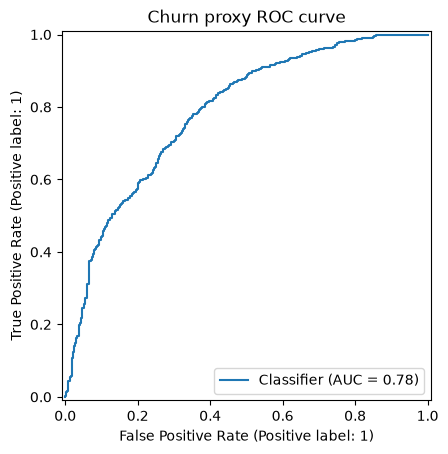

,Predicted active,Predicted churn proxy
Actual active,384,189
Actual churn proxy,194,554


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             RocCurveDisplay, precision_recall_fscore_support)

feature_cols = ["Recency", "Frequency", "Monetary", "MeanBasketUnits", "UniqueProducts"]
X = churn_features[feature_cols]
y = churn_features["ChurnProxy"]

if y.nunique() == 2 and y.value_counts().min() >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
    )
    churn_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE,
            min_samples_leaf=2
        ))
    ])
    churn_model.fit(X_train, y_train)
    y_pred = churn_model.predict(X_test)
    y_prob = churn_model.predict_proba(X_test)[:, 1]
    print(classification_report(y_test, y_pred, zero_division=0))
    if y_test.nunique() == 2:
        print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
        RocCurveDisplay.from_predictions(y_test, y_prob)
        plt.title("Churn proxy ROC curve")
        plt.show()
    display(pd.DataFrame(confusion_matrix(y_test, y_pred),
                         index=["Actual active", "Actual churn proxy"],
                         columns=["Predicted active", "Predicted churn proxy"]))
else:
    print("Churn model skipped: proxy label has insufficient class diversity.")
    churn_model = None

In [20]:
daily_total = sales_df.groupby(sales_df["InvoiceDate"].dt.floor("D"))["Quantity"].sum()
daily_total = daily_total.asfreq("D", fill_value=0).sort_index()
forecast_df = daily_total.rename("y").reset_index().rename(columns={"InvoiceDate": "ds"})
forecast_df = forecast_df.sort_values("ds")
split_idx = max(1, int(len(forecast_df) * 0.8))
train_ts = forecast_df.iloc[:split_idx].copy()
test_ts = forecast_df.iloc[split_idx:].copy()
print("Train period:", train_ts["ds"].min(), "to", train_ts["ds"].max())
print("Test period:", test_ts["ds"].min(), "to", test_ts["ds"].max())

Train period: 2009-12-01 00:00:00 to 2011-07-14 00:00:00
Test period: 2011-07-15 00:00:00 to 2011-12-09 00:00:00


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

                                                                  
naive_pred = np.repeat(train_ts["y"].iloc[-1], len(test_ts))
mae = mean_absolute_error(test_ts["y"], naive_pred)
rmse = mean_squared_error(test_ts["y"], naive_pred) ** 0.5
nonzero_mask = test_ts["y"] != 0
mape = (np.abs((test_ts.loc[nonzero_mask, "y"] - naive_pred[nonzero_mask]) /
               test_ts.loc[nonzero_mask, "y"]).mean() * 100) if nonzero_mask.any() else np.nan
print(f"Naive baseline MAE: {mae:.3f}")
print(f"Naive baseline RMSE: {rmse:.3f}")
print(f"MAPE on nonzero actuals: {mape:.2f}%")

Naive baseline MAE: 10549.831
Naive baseline RMSE: 13782.007
MAPE on nonzero actuals: 44.34%


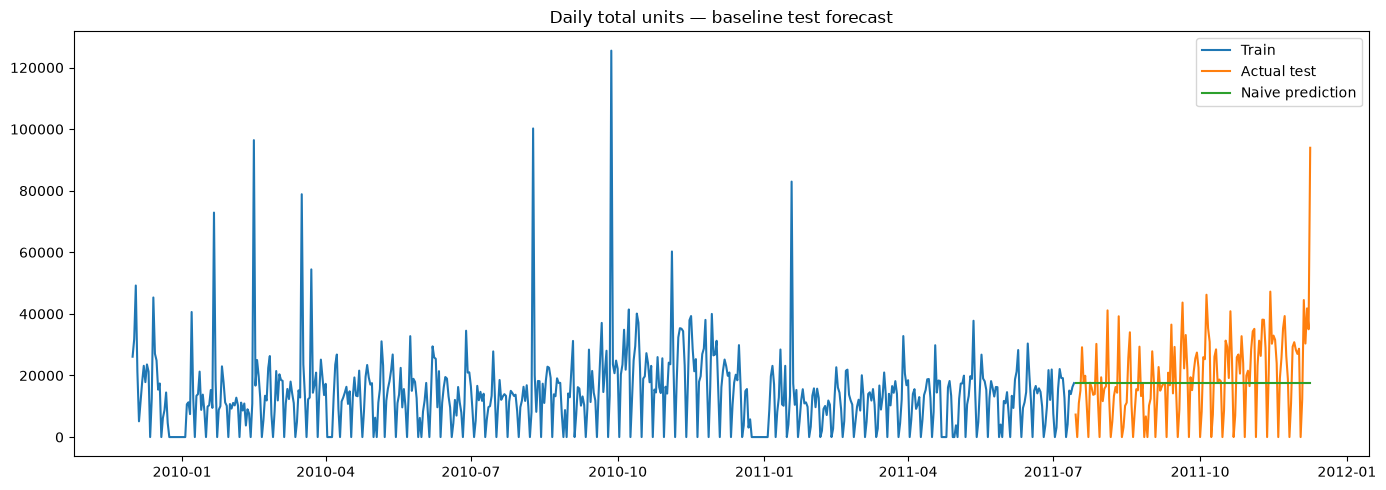

In [22]:
plt.figure(figsize=(14, 5))
plt.plot(train_ts["ds"], train_ts["y"], label="Train")
plt.plot(test_ts["ds"], test_ts["y"], label="Actual test")
plt.plot(test_ts["ds"], naive_pred, label="Naive prediction")
plt.title("Daily total units — baseline test forecast")
plt.legend()
plt.tight_layout()
plt.show()

Importing plotly failed. Interactive plots will not work.
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
14:11:13 - cmdstanpy - INFO - Chain [1] start processing
14:11:14 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAE: 6835.504
Prophet RMSE: 10329.449


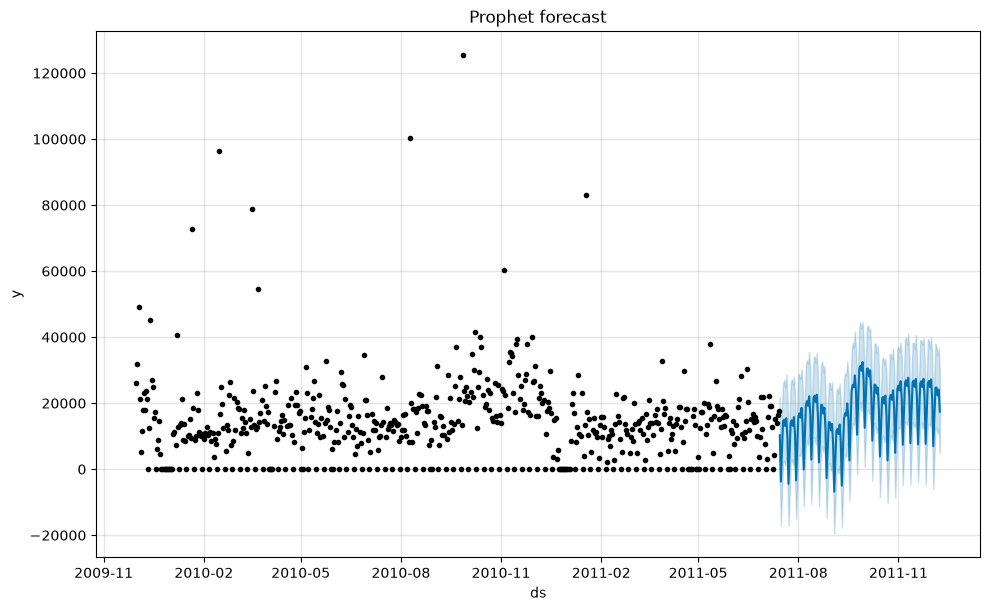

In [23]:
prophet_model = None
prophet_forecast = None
try:
    from prophet import Prophet
    prophet_model = Prophet(
        yearly_seasonality=True, weekly_seasonality=True,
        daily_seasonality=False
    )
    prophet_model.fit(train_ts[["ds", "y"]])
    prophet_forecast = prophet_model.predict(test_ts[["ds"]])
    prophet_pred = prophet_forecast["yhat"].clip(lower=0).to_numpy()
    print("Prophet MAE:", round(mean_absolute_error(test_ts["y"], prophet_pred), 3))
    print("Prophet RMSE:", round(mean_squared_error(test_ts["y"], prophet_pred) ** 0.5, 3))
    prophet_model.plot(prophet_forecast)
    plt.title("Prophet forecast")
    plt.show()
except ImportError:
    print("Prophet is not installed. Install with: %pip install prophet")
except Exception as exc:
    print("Prophet stage encountered an issue:", repr(exc))

In [24]:
lstm_model = None
lstm_results = None
try:
    from sklearn.preprocessing import MinMaxScaler
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping

    values = forecast_df["y"].to_numpy(dtype=float).reshape(-1, 1)
    scaler = MinMaxScaler()
    train_values = scaler.fit_transform(values[:split_idx])
    test_values = scaler.transform(values[split_idx:])
    window = 14

    def make_sequences(arr, window_size):
        Xs, ys = [], []
        for i in range(window_size, len(arr)):
            Xs.append(arr[i-window_size:i, 0])
            ys.append(arr[i, 0])
        return np.array(Xs), np.array(ys)

    X_lstm_train, y_lstm_train = make_sequences(train_values, window)
                                                                  
    combined = np.vstack([train_values[-window:], test_values])
    X_lstm_test, y_lstm_test = make_sequences(combined, window)
    X_lstm_train = X_lstm_train.reshape(-1, window, 1)
    X_lstm_test = X_lstm_test.reshape(-1, window, 1)

    if len(X_lstm_train) > 0 and len(X_lstm_test) > 0:
        lstm_model = Sequential([
            LSTM(64, input_shape=(window, 1), return_sequences=False),
            Dropout(0.2),
            Dense(32, activation="relu"),
            Dense(1)
        ])
        lstm_model.compile(optimizer="adam", loss="mse")
        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        lstm_model.fit(X_lstm_train, y_lstm_train, epochs=30, batch_size=32,
                       validation_split=0.1, callbacks=[early_stop], verbose=1)
        lstm_scaled_pred = lstm_model.predict(X_lstm_test, verbose=0)
        lstm_pred = scaler.inverse_transform(lstm_scaled_pred).ravel().clip(min=0)
        lstm_actual = scaler.inverse_transform(y_lstm_test.reshape(-1, 1)).ravel()
        lstm_results = {
            "MAE": mean_absolute_error(lstm_actual, lstm_pred),
            "RMSE": mean_squared_error(lstm_actual, lstm_pred) ** 0.5
        }
        print({k: round(v, 3) for k, v in lstm_results.items()})
except ImportError:
    print("TensorFlow is not installed. Install with: %pip install tensorflow")
except Exception as exc:
    print("LSTM stage encountered an issue:", repr(exc))

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0130 - val_loss: 0.0038
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0108 - val_loss: 0.0040
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - val_loss: 0.0036
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0105 - val_loss: 0.0037
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0104 - val_loss: 0.0036
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - val_loss: 0.0038
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - val_loss: 0.0038
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0104 - val_loss: 0.0038
{'MAE': 10703.276, 'RMSE': 14043.138}


In [25]:
LEAD_TIME_DAYS = 7
SERVICE_FACTOR = 1.65                                                           
REVIEW_PERIOD_DAYS = 7

product_daily = daily_product_demand.groupby("StockCode").agg(
    mean_daily_demand=("daily_units", "mean"),
    std_daily_demand=("daily_units", "std"),
    total_units=("daily_units", "sum"),
    active_days=("Date", "nunique")
).reset_index()

product_daily["std_daily_demand"] = product_daily["std_daily_demand"].fillna(0)
product_daily["safety_stock"] = SERVICE_FACTOR * product_daily["std_daily_demand"] * np.sqrt(LEAD_TIME_DAYS)
product_daily["reorder_point"] = (
    product_daily["mean_daily_demand"] * LEAD_TIME_DAYS + product_daily["safety_stock"]
)
product_daily["target_stock"] = (
    product_daily["mean_daily_demand"] * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
    + product_daily["safety_stock"]
)
product_daily["suggested_order_qty"] = np.ceil(product_daily["target_stock"]).astype(int)

product_revenue = sales_df.groupby("StockCode")["Revenue"].sum().rename("total_revenue")
product_daily = product_daily.merge(product_revenue, on="StockCode", how="left")
product_daily = product_daily.sort_values("total_revenue", ascending=False)
display(product_daily.head(20))

,StockCode,mean_daily_demand,std_daily_demand,total_units,active_days,safety_stock,reorder_point,target_stock,suggested_order_qty,total_revenue
4902,M,25.543767,126.337457,9630,377,551.524862,730.331228,9.091376e+02,910,339599.81
1513,22423,51.513619,53.790301,26478,514,234.821004,595.416334,9.560117e+02,957,330590.32
4901,DOT,3.208617,3.652772,1415,441,15.946139,38.406456,6.086677e+01,61,309854.11
4456,85123A,156.223881,214.709983,94203,603,937.314210,2030.881375,3.124449e+03,3125,257724.71
4441,85099B,164.273345,181.853781,96757,589,793.880800,1943.794213,3.093708e+03,3094,180569.34
2673,23843,80995.000000,0.000000,80995,1,0.000000,566965.000000,1.133930e+06,1133930,168469.60
2817,47566,52.125693,64.449139,28200,541,281.352052,646.231904,1.011112e+03,1012,148318.28
3132,84879,137.597938,240.517450,80082,582,1049.976440,2013.162007,2.976348e+03,2977,129324.49
4904,POST,10.433852,8.405912,5363,514,36.695922,109.732887,1.827699e+02,183,125682.42
1201,22086,114.653595,176.960580,35084,306,772.519582,1575.094746,2.377670e+03,2378,117760.29


<Figure size 1000x500 with 0 Axes>

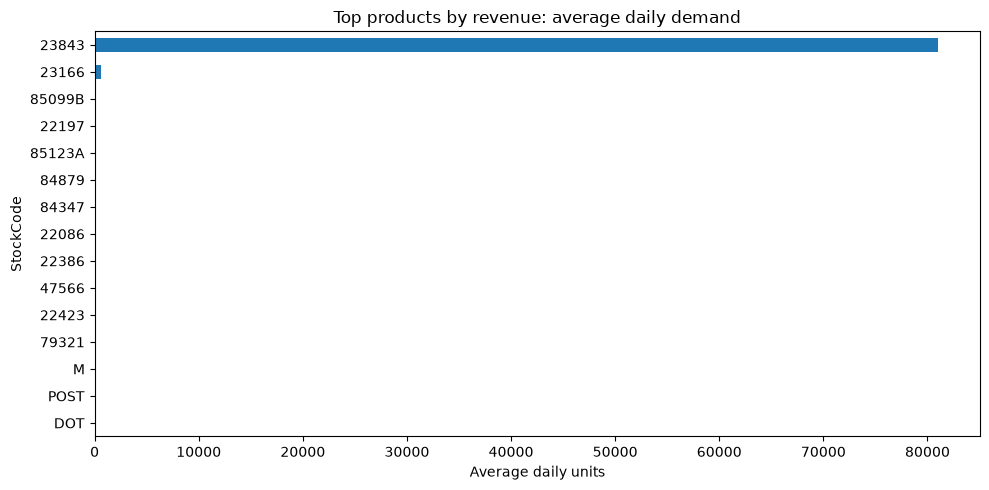

In [26]:
plt.figure(figsize=(10, 5))
product_daily.head(15).sort_values("mean_daily_demand").plot(
    x="StockCode", y="mean_daily_demand", kind="barh", legend=False, figsize=(10, 5)
)
plt.title("Top products by revenue: average daily demand")
plt.xlabel("Average daily units")
plt.tight_layout()
plt.show()

In [27]:
print("PERIOD:", sales_df["InvoiceDate"].min().date(), "to", sales_df["InvoiceDate"].max().date())
print(f"Revenue: {sales_df['Revenue'].sum():,.2f}")
print(f"Units sold: {sales_df['Quantity'].sum():,.0f}")
print(f"Customers with ID: {sales_df['Customer ID'].nunique():,}")
print(f"Most revenue-generating country: {sales_df.groupby('Country')['Revenue'].sum().idxmax()}")
print(f"Top revenue product code: {sales_df.groupby('StockCode')['Revenue'].sum().idxmax()}")
if not rfm.empty:
    print("Largest RFM segment:", rfm["Segment"].value_counts().idxmax())

PERIOD: 2009-12-01 to 2011-12-09
Revenue: 20,476,634.02
Units sold: 11,205,149
Customers with ID: 5,878
Most revenue-generating country: United Kingdom
Top revenue product code: M
Largest RFM segment: Lost / Hibernating


In [28]:
                                                                      
sales_df.to_csv(OUTPUT_DIR / "cleaned_sales.csv", index=False)
monthly_sales.to_csv(OUTPUT_DIR / "monthly_sales_summary.csv", index=False)
rfm.to_csv(OUTPUT_DIR / "customer_rfm_segments.csv", index=False)
churn_features.to_csv(OUTPUT_DIR / "churn_proxy_features.csv", index=False)
daily_total.rename("daily_units").to_csv(OUTPUT_DIR / "daily_total_demand.csv")
product_daily.to_csv(OUTPUT_DIR / "inventory_reorder_recommendations.csv", index=False)

print("Exported processed files to:", OUTPUT_DIR.resolve())

Exported processed files to: D:\ProjectMaterail\RetailPulse\data\processed


In [29]:
                                            
if churn_model is not None:
    joblib.dump(churn_model, MODEL_DIR / "churn_proxy_model.joblib")
    print("Saved churn model:", MODEL_DIR / "churn_proxy_model.joblib")

                                            
if prophet_model is not None:
    try:
        import json
        from prophet.serialize import model_to_json
        with open(MODEL_DIR / "prophet_demand_model.json", "w", encoding="utf-8") as f:
            f.write(model_to_json(prophet_model))
        print("Saved Prophet model.")
    except Exception as exc:
        print("Prophet model export skipped:", repr(exc))

                                         
if lstm_model is not None:
    try:
        lstm_model.save(MODEL_DIR / "lstm_demand_model.keras")
        print("Saved LSTM model.")
    except Exception as exc:
        print("LSTM model export skipped:", repr(exc))

Saved churn model: ..\models\churn_proxy_model.joblib
Saved Prophet model.
Saved LSTM model.


In [30]:
try:
    import mlflow
    mlflow.set_experiment("RetailPulse")
    with mlflow.start_run(run_name="baseline_retail_analytics"):
        mlflow.log_param("dataset", "Online Retail II")
        mlflow.log_param("forecast_target", "aggregate daily quantity")
        mlflow.log_param("forecast_model", "naive baseline")
        mlflow.log_metric("baseline_MAE", float(mae))
        mlflow.log_metric("baseline_RMSE", float(rmse))
        if not np.isnan(mape):
            mlflow.log_metric("baseline_MAPE_nonzero", float(mape))
        mlflow.log_artifact(str(OUTPUT_DIR / "monthly_sales_summary.csv"))
    print("Baseline experiment logged to MLflow.")
except ImportError:
    print("MLflow is not installed. Install with: %pip install mlflow")
except Exception as exc:
    print("MLflow tracking skipped:", repr(exc))

Baseline experiment logged to MLflow.


In [31]:
                                                                              
                                                
def population_stability_index(expected, actual, bins=10):
    expected = pd.Series(expected).dropna().astype(float)
    actual = pd.Series(actual).dropna().astype(float)
    if expected.empty or actual.empty:
        return np.nan
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    e_counts = np.histogram(expected, bins=edges)[0]
    a_counts = np.histogram(actual, bins=edges)[0]
    e_pct = np.clip(e_counts / max(e_counts.sum(), 1), 1e-6, None)
    a_pct = np.clip(a_counts / max(a_counts.sum(), 1), 1e-6, None)
    return float(np.sum((a_pct - e_pct) * np.log(a_pct / e_pct)))

                                                                              
cutoff = sales_df["InvoiceDate"].quantile(0.7)
early_qty = sales_df.loc[sales_df["InvoiceDate"] <= cutoff, "Quantity"]
late_qty = sales_df.loc[sales_df["InvoiceDate"] > cutoff, "Quantity"]
psi_quantity = population_stability_index(early_qty, late_qty)
print("PSI for transaction quantity (early vs later period):", psi_quantity)

PSI for transaction quantity (early vs later period): 0.003541206289600414
